# FIRELINE — Audit dataset & batas wilayah

Notebook 05 adalah pintu masuk paket peta prioritas. Kita menjawab **data ini sebenarnya mengamati apa, kapan, dan di mana?** Semua angka dihitung dari berkas lokal yang tercantum dalam konfigurasi. Dataset utama tetap NASA FIRMS VIIRS NOAA-20.

Ini analisis historis untuk fitur 02 keputusan PMA/UX. Riwayat notebook Maria 01–04 dipertahankan untuk referensi; angka resminya untuk paket ini berasal dari notebook 05–06.

Urutan baca: arti satu baris → audit kualitas → batas wilayah → cakupan waktu → makna untuk produk.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd() if (Path.cwd() / "fireline").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from fireline.pipeline import settings, audit, build
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
config = settings(ROOT / "config.local.json")

## 1. Arti satu baris

`latitude` (lintang) seperti posisi atas–bawah pada globe: utara atau selatan khatulistiwa. `longitude` (bujur) adalah posisi timur–barat. Keduanya bersama-sama menentukan posisi, bukan skor bahaya.

Satu baris adalah observasi anomali panas satelit. Satu kejadian dapat menghasilkan banyak baris, dari beberapa piksel atau lintasan. FRP dalam MW mengukur daya radiasi panas; `scan × track` adalah footprint piksel pengamatan dan tidak kita ubah menjadi luas terbakar.

`acq_date` dan `acq_time` diparsing sebagai UTC (HHMM, termasuk nol di depan). Dashboard menampilkan waktu observasi lokal WIB/WITA sesuai provinsi; pengelompokan hari tetap UTC agar batas hari konsisten.

In [2]:
raw, accepted, unmatched, invalid, provinces, stages = audit(config)
display(raw.head(5))
display(stages)
assert stages.removed.sum() + len(accepted) == len(raw)
display(Markdown(f"**{len(raw):,} observasi mentah → {len(accepted):,} di dalam poligon BIG Kalimantan.**"))

E:\DSA-FINAL\checkpoint_3\Fireline-priority-map\.venv\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: OGRGeoJSONReadRawPoint(): too many members in array '[ 110.20399999999999, -3.0646, 0.0, null ]': 4. At most 3 are handled. Ignoring extra members. Further messages of this type will be suppressed.
  return ogr_read(


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type,source_row
0,-2.06932,110.91480,342.89,0.52,0.41,2024-08-01,545,N20,VIIRS,n,2,295.59,32.35,D,0,0
1,-2.06552,110.91424,335.58,0.52,0.41,2024-08-01,545,N20,VIIRS,n,2,298.05,60.85,D,0,1
2,-1.53228,114.34785,332.34,0.39,0.36,2024-08-01,545,N20,VIIRS,n,2,296.86,2.77,D,0,2
3,-0.87858,115.03748,334.21,0.38,0.36,2024-08-01,545,N20,VIIRS,n,2,296.66,2.61,D,0,3
4,-0.87527,115.03698,342.37,0.38,0.36,2024-08-01,545,N20,VIIRS,n,2,298.42,14.55,D,0,4


,stage,retained,removed
0,Mentah,61583,0
1,Duplikat persis dihapus,61583,0
2,Koordinat dan waktu valid,61583,0
3,Type 0 (dugaan api vegetasi),61583,0
4,Di dalam poligon BIG Kalimantan,60708,875


**61,583 observasi mentah → 60,708 di dalam poligon BIG Kalimantan.**

## 2. Mengapa angka dari branch berbeda?

Filter kotak wilayah dapat menerima titik di pulau lain atau menolak bagian Kalimantan jika kotaknya terlalu sempit. Sekarang kami memasangkan **koordinat setiap observasi** ke poligon lima provinsi BIG, sebelum membentuk grid.

Titik yang tidak cocok disimpan untuk audit; tidak otomatis dilabeli error GPS. Alasannya bisa wilayah di luar cakupan, pesisir, perbatasan, atau perbedaan geometri referensi. Titik tepat di batas dua provinsi dihitung sekali dengan label deterministik. Poligon kab/kota Kaka hanya membantu tampilan/detail; tidak menentukan scope utama.

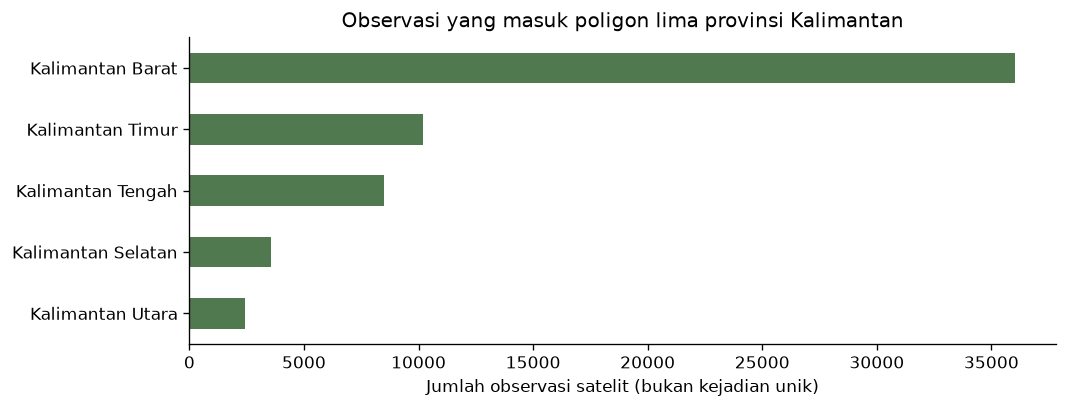

,observations
province_name,
Kalimantan Utara,2437
Kalimantan Selatan,3583
Kalimantan Tengah,8478
Kalimantan Timur,10191
Kalimantan Barat,36019


,latitude,longitude,acq_date,acq_time
190,-3.27431,116.10246,2024-08-01,1827
191,-2.53903,119.31428,2024-08-02,526
503,-3.75561,116.31831,2024-08-05,610
1368,1.03944,111.85069,2024-08-11,559
1386,0.08456,117.48351,2024-08-11,1658
1426,-1.63316,108.95851,2024-08-12,539
1548,-2.43397,119.44762,2024-08-13,520
1909,-2.02871,119.37820,2024-08-15,442


Jumlah belum cocok poligon: 875


In [3]:
counts = accepted.groupby("province_name").size().sort_values()
fig, ax = plt.subplots(figsize=(9, 3.5))
counts.plot.barh(ax=ax, color="#517950")
ax.set_xlabel("Jumlah observasi satelit (bukan kejadian unik)")
ax.set_ylabel("")
ax.set_title("Observasi yang masuk poligon lima provinsi Kalimantan")
plt.tight_layout(); plt.show()
display(counts.rename("observations").to_frame())
display(unmatched[["latitude","longitude","acq_date","acq_time"]].head(8))
print("Jumlah belum cocok poligon:", len(unmatched))

## 3. Periode yang benar-benar tersedia

Perbandingan antar-tahun perlu periode sebanding. Hitungan bulanan gabungan dapat berat sebelah karena 2024 dimulai Agustus dan 2026 berakhir Mei. Grafik berikut menampilkan tahun dan bulan terpisah. Hari tanpa observasi dalam CSV tidak membuktikan sensor memperoleh cakupan penuh atau tidak ada api.

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2024,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3525.0,16750.0,3673.0,523.0,150.0
2025,113.0,293.0,236.0,210.0,685.0,664.0,7435.0,7250.0,9004.0,2595.0,692.0,162.0
2026,1985.0,634.0,2504.0,968.0,657.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


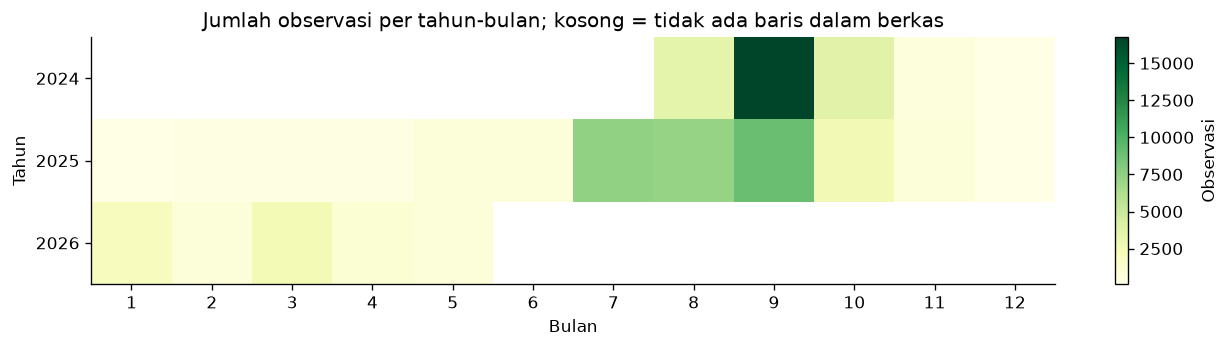

Rentang **2024-08-01 – 2026-05-31 UTC**. Puncak harian **2024-09-03**, sebanyak **2,399 observasi**.

In [4]:
accepted["year"] = pd.to_datetime(accepted.date).dt.year
accepted["month"] = pd.to_datetime(accepted.date).dt.month
coverage = accepted.groupby(["year","month"]).size().unstack().reindex(columns=range(1,13))
display(coverage)
fig, ax = plt.subplots(figsize=(11,3))
im=ax.imshow(coverage, cmap="YlGn", aspect="auto")
ax.set_xticks(range(12), labels=range(1,13)); ax.set_yticks(range(len(coverage)), labels=coverage.index)
ax.set_xlabel("Bulan"); ax.set_ylabel("Tahun")
ax.set_title("Jumlah observasi per tahun-bulan; kosong = tidak ada baris dalam berkas")
fig.colorbar(im, ax=ax, label="Observasi")
plt.tight_layout(); plt.show()
daily = accepted.groupby("date").size()
display(Markdown(f"Rentang **{accepted.date.min()} – {accepted.date.max()} UTC**. Puncak harian **{daily.idxmax()}**, sebanyak **{daily.max():,} observasi**."))

## 4. Confidence, waktu deteksi, dan batas kesimpulan

Confidence membantu membaca kualitas deteksi. Ia tidak membuktikan kebenaran laporan warga dan tidak langsung mengukur urgensi respons. Pengamatan malam hanya menunjukkan waktu deteksi; jenis gambut belum dapat dipastikan.

Selang lintasan satelit tidak mengukur lama verifikasi relawan. Untuk menguji klaim 12–24 jam, dibutuhkan timestamp laporan, penugasan, dan hasil pengecekan lapangan. Dataset ini tidak menyediakan rangkaian tersebut.

In [5]:
display(accepted.confidence.value_counts().rename("observations").to_frame())
display(accepted.groupby("daynight").size().rename("observations").to_frame())
display(accepted.frp.describe(percentiles=[.5,.9,.95,.99]).to_frame("FRP_MW"))
print("FRP tidak tersedia:", accepted.frp.isna().sum())
print("Koordinat/waktu tidak valid:", len(invalid))
print("Titik tepat di batas bersama:", accepted.border_ambiguous.sum())

,observations
confidence,
n,56458
h,2313
l,1937


,observations
daynight,
D,54175
N,6533


,FRP_MW
count,60708.000000
mean,10.640125
std,17.526986
min,0.090000
50%,6.180000
90%,22.250000
95%,33.136500
99%,70.836500
max,954.790000


FRP tidak tersedia: 0
Koordinat/waktu tidak valid: 0
Titik tepat di batas bersama: 0


## 5. Apa yang digunakan produk?

Hasil audit menyediakan populasi observasi yang jelas untuk peta. Dataset di luar poligon tetap tersimpan sebagai bahan penelusuran, tidak masuk Top 10. Jumlah observasi belum sama dengan jumlah kebakaran; karena itu notebook berikut membentuk area-hari.

Sumber: [NASA FIRMS](https://firms.modaps.eosdis.nasa.gov/active_fire/), [BIG Batas Provinsi](https://geoservices.big.go.id/gis/rest/services/STIG/Batas_Provinsi/MapServer). Snapshot dan SHA-256 dicatat ketika notebook 06 dijalankan.